# 08_05 — Improving the virtual diagnostic: where the large errors come from, and what fixes them

Starting point: the best model of 08_03/08_04 (**two-stage, MLP · CCC**), whose difference to the BCM has a std of up
to ~235 pC in the high-charge segments.

1. **Diagnosis** — split the difference into a **slow** part (its 51-shot rolling mean: trend / calibration error)
   and a **fast** part (the rest: shot-to-shot error)
2. **How low can it go?** — the BCM's own noise floor in pC, from three instruments that see the same charge
3. **Approaches**, all on the same chronological test (train before the cut, infer after; choices made on a validation
   block, never on the test shots):
   - **A** — the starting point (stage 1 trained on all training shots + MLP · CCC, 3 seeds)
   - **B** — stage 1 trained on the **most recent shots only** (window chosen on validation) — targets the slow part
   - **C** — B + MLP · CCC averaged over **6 seeds**
   - **D** — C + a **second model that predicts the difference** (residual model), trained on out-of-fold differences
   - **E** — one stage-2 model **pooled over all segments** (relative units), instead of one per segment
   - **F** — B + MLP trained on **MSE** (6 seeds): MSE directly minimises the spread of the difference
4. Results in pC, and the improved predictions saved for 08_04

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_num_threads(8)

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASETS = REPO / "results" / "datasets"
OUT = REPO / "results" / "virtual_diagnostic"
FIGS = OUT / "improvements"
FIGS.mkdir(parents=True, exist_ok=True)

CUT, VAL_FRACTION, K = 0.7, 0.2, 51
WINDOWS = [None, 4000, 2000, 1000]   # stage 1: train on all shots or on the last W before the end of the training data
N_FOLDS = 4                          # residual model: forward-chaining folds for the out-of-fold differences
MIN_VALID, NO_BEAM, PC = 500, 0.2, 1000

INK, MUTED, GRID = "#2b2b29", "#8a8985", "#e6e5e1"
BEFORE, AFTER, FLOOR = "#8a8985", "#eb6834", "#2b2b29"

manifest = json.loads((DATASETS / "manifest.json").read_text())
FEATURES = manifest["features"]
LAB, BTV = FEATURES.index("lab_laser_power"), FEATURES.index("BTV_intensity")

## Building blocks (same as 08_03)

In [2]:
def past_mean(a):
    return pd.DataFrame(a).shift(1).rolling(K, min_periods=1).mean().bfill().to_numpy()


def smooth(a):
    return pd.Series(a).rolling(K, center=True, min_periods=1).mean().to_numpy()


def fast(a):
    return a - smooth(a)


class LinearPlusTrees(BaseEstimator, RegressorMixin):
    def __init__(self, linear, trees):
        self.linear, self.trees = linear, trees

    def fit(self, X, y):
        self.linear_ = clone(self.linear).fit(X, y)
        self.trees_ = clone(self.trees).fit(X, y - self.linear_.predict(X))
        return self

    def predict(self, X):
        return self.linear_.predict(X) + self.trees_.predict(X)


def ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13)))


def hgb(**kw):
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=50,
                                         l2_regularization=1.0, random_state=0, **kw)


def loss_ccc(p, t):
    pm, tm = p.mean(), t.mean()
    return 1 - 2 * ((p - pm) * (t - tm)).mean() / (p.var(unbiased=False) + t.var(unbiased=False) + (pm - tm) ** 2)


def loss_mse(p, t):
    return ((p - t) ** 2).mean()


class MLP(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 64), nn.GELU(), nn.Dropout(0.1),
                                 nn.Linear(64, 64), nn.GELU(), nn.Dropout(0.1), nn.Linear(64, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def train_mlp(loss, Xin, target, fit, val, seed):
    torch.manual_seed(seed)
    model = MLP(Xin.shape[1])
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    Xt, Tt = torch.tensor(Xin, dtype=torch.float32), torch.tensor(target, dtype=torch.float32)
    i_fit, i_val = np.flatnonzero(fit), np.flatnonzero(val)
    rng = np.random.default_rng(seed)
    best, state, wait = np.inf, None, 0
    for _ in range(200):
        model.train()
        for b in np.array_split(rng.permutation(i_fit), max(1, len(i_fit) // 256)):
            opt.zero_grad()
            loss(model(Xt[b]), Tt[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            lv = loss(model(Xt[i_val]), Tt[i_val]).item()
        if lv < best - 1e-5:
            best, state, wait = lv, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= 15:
                break
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        return model(Xt).numpy()


def standardise(a, ref):
    return np.nan_to_num((a - np.nanmean(a[ref], 0)) / (np.nanstd(a[ref], 0) + 1e-12))


def stage1(s, train, end_row, window):
    """08_01 model on the training shots (optionally only the last `window` before end_row) -> prediction, trend."""
    use = train & (s["rows"] >= (end_row - window if window else 0))
    p = LinearPlusTrees(ridge(), hgb()).fit(s["X"][use], s["y"][use]).predict(s["X"])
    return p, past_mean(p[:, None])[:, 0]


def stage2(s, fit, val, loss=loss_ccc, seeds=(0, 1, 2)):
    """MLP on this segment: predicted deviation from the previous 51 shots, for every row."""
    Xin = np.hstack([standardise(s["X_dev"], fit), standardise(s["X"], fit)])
    tm, ts = s["y_dev"][fit].mean(), s["y_dev"][fit].std()
    out = np.mean([train_mlp(loss, Xin, (s["y_dev"] - tm) / ts, fit, val, sd) for sd in seeds], axis=0) * ts + tm
    return out + np.mean(s["y_dev"][fit] - out[fit])


def scores_pc(y, p):
    e = PC * (p - y)
    slow = smooth(e)
    fy, fp = fast(y), fast(p)
    return {"std [pC]": e.std(), "bias [pC]": e.mean(), "slow [pC]": slow.std(), "fast [pC]": (e - slow).std(),
            "fluct CCC": 2 * np.cov(fy, fp, bias=True)[0, 1] / (fy.var() + fp.var() + (fy.mean() - fp.mean()) ** 2)}

In [3]:
segments = {}
for info in manifest["segments"]:
    z = np.load(DATASETS / info["file"])
    X, y, v = z["X"], z["y"], z["valid"]
    if v.sum() < MIN_VALID:
        continue
    n = len(y)
    rows = np.arange(n)
    cut = int(CUT * n)
    val_row = int((1 - VAL_FRACTION) * cut)
    beam = y > NO_BEAM * np.median(y[v & (rows < cut)])
    good = v & beam
    segments[info["segment"]] = {
        "run": info["run"], "X": X, "y": y, "rows": rows, "cut": cut, "val_row": val_row,
        "fit": good & (rows < val_row), "val": good & (rows >= val_row) & (rows < cut),
        "train": good & (rows < cut), "test": good & (rows >= cut),
        "X_dev": X - past_mean(X), "y_dev": y - past_mean(y[:, None])[:, 0],
    }
print(f"{len(segments)} segments: {list(segments)}")

7 segments: [0, 1, 3, 4, 5, 6, 7]


## 1. Diagnosis of the starting point

From `predictions_08_03.csv` (MLP · CCC). **slow** = 51-shot rolling mean of the difference (trend / calibration
error), **fast** = difference − slow (shot-to-shot error).

In [4]:
start = pd.read_csv(OUT / "predictions_08_03.csv")
diag = {}
for k, d in start.groupby("segment"):
    e = PC * (d["MLP · CCC"] - d["measured"]).to_numpy()
    slow = smooth(e)
    diag[k] = {"std [pC]": e.std(), "slow [pC]": slow.std(), "slow mean (bias) [pC]": slow.mean(),
               "fast [pC]": (e - slow).std(), "share of the variance from slow": slow.var() / e.var()}
diag = pd.DataFrame(diag).T.rename_axis("segment")
diag.style.format({c: "{:.1f}" for c in diag.columns if "[pC]" in c} | {"share of the variance from slow": "{:.0%}"})

,std [pC],slow [pC],slow mean (bias) [pC],fast [pC],share of the variance from slow
segment,,,,,
0,12.8,4.7,-9.3,11.8,13%
1,195.7,160.8,157.5,110.3,68%
3,12.7,3.3,-2.2,12.1,7%
4,12.7,2.8,-0.4,12.4,5%
5,134.4,49.5,2.9,124.7,14%
6,49.9,36.4,17.8,33.4,53%
7,234.9,51.8,-55.8,228.6,5%


Segment 1 (and 6) is dominated by the **slow** part (calibration drifts during the test period);
segments 5 and 7 by the **fast** part.

## 2. How low can the difference go? The BCM's own noise

Three instruments see the same charge with independent noise: BCM, screen (`BTV_intensity`), laser energy
(`lab_laser_power`). The real-charge share of the BCM's shot-to-shot variance is `cov(A,B)·cov(A,C) / (cov(B,C)·var A)`
(three-cornered hat, as in 08_02); the rest is BCM noise. In pC: **noise floor = √(1 − share) × std of the BCM's
shot-to-shot fluctuation**. No model can bring the *fast* part of the difference below this, because a perfect model
would still differ from the BCM by the BCM's own noise. Approximate (linear relations, independent noise assumed).

In [5]:
floor = {}
for k, s in segments.items():
    t = s["test"] & ~np.isnan(s["X"][:, BTV])
    a, b, c = fast(s["y"][t]), fast(s["X"][t, BTV]), fast(s["X"][t, LAB])
    C = np.cov([a, b, c])
    share = C[0, 1] * C[0, 2] / C[1, 2] / C[0, 0]
    floor[k] = {"real-charge share": share, "BCM noise floor [pC]": PC * np.sqrt(max(1 - share, 0)) * a.std()}
floor = pd.DataFrame(floor).T.rename_axis("segment")
floor.style.format({"real-charge share": "{:.0%}", "BCM noise floor [pC]": "{:.1f}"})

,real-charge share,BCM noise floor [pC]
segment,,
0,63%,13.2
1,66%,95.6
3,46%,11.1
4,39%,11.7
5,64%,103.9
6,96%,30.3
7,83%,260.8


## 3. Approaches (~4 min)

In [6]:
t0 = time.time()
preds, s1_window = {k: {} for k in segments}, {}

for k, s in segments.items():
    # stage 1 window: the one with the smallest trend error on the validation block, fitted on the shots before it
    errs = {}
    for w in WINDOWS:
        p, _ = stage1(s, s["fit"], s["val_row"], w)
        errs[w] = np.sqrt(np.mean((smooth(s["y"][s["val"]]) - smooth(p[s["val"]])) ** 2))
    s1_window[k] = min(errs, key=errs.get)
    _, trend_all = stage1(s, s["train"], s["cut"], None)
    _, trend_recent = stage1(s, s["train"], s["cut"], s1_window[k])

    ccc3 = stage2(s, s["fit"], s["val"])
    ccc6 = np.mean([ccc3, stage2(s, s["fit"], s["val"], seeds=(3, 4, 5))], axis=0)
    mse6 = stage2(s, s["fit"], s["val"], loss=loss_mse, seeds=range(6))
    preds[k]["A: start (08_03)"] = trend_all + ccc3
    preds[k]["B: recent stage 1"] = trend_recent + ccc3
    preds[k]["C: B + 6 seeds"] = trend_recent + ccc6
    preds[k]["F: B + MSE, 6 seeds"] = trend_recent + mse6
    print(f"segment {k}: stage-1 window {s1_window[k] or 'all'}, {time.time() - t0:.0f} s")

segment 0: stage-1 window 2000, 10 s


segment 1: stage-1 window 4000, 22 s


segment 3: stage-1 window 1000, 31 s


segment 4: stage-1 window all, 37 s


segment 5: stage-1 window 4000, 49 s


segment 6: stage-1 window 2000, 57 s


segment 7: stage-1 window all, 66 s


### D — a second model that predicts the difference

The difference of the training shots themselves is not usable (the model has seen them: it is too small and does not
look like the test difference). So the training shots are split in time blocks; for each block, the C pipeline is
fitted on the blocks **before** it and predicts it → **out-of-fold** differences, like the ones on unseen shots.
A residual model (Ridge, or gradient boosting with absolute-error loss) learns these differences from the features
and C's own prediction, and is added to C.

In [7]:
for k, s in segments.items():
    tr = np.flatnonzero(s["train"])
    blocks = np.array_split(tr, N_FOLDS + 1)
    oof = np.full(len(s["y"]), np.nan)
    for j in range(1, N_FOLDS + 1):
        before = np.zeros(len(s["y"]), bool)
        before[np.concatenate(blocks[:j])] = True
        split = int(np.percentile(np.flatnonzero(before), 80))
        fit_j, val_j = before & (s["rows"] < split), before & (s["rows"] >= split)
        _, trend_j = stage1(s, before, blocks[j][0], s1_window[k])
        dev_j = np.mean([stage2(s, fit_j, val_j), stage2(s, fit_j, val_j, seeds=(3, 4, 5))], axis=0)
        oof[blocks[j]] = (trend_j + dev_j)[blocks[j]]
    base = preds[k]["C: B + 6 seeds"]
    feats = np.column_stack([s["X"], s["X_dev"], base, past_mean(base[:, None])[:, 0]])
    have = ~np.isnan(oof)
    for name, model in [("Ridge", ridge()), ("boosting", hgb(loss="absolute_error"))]:
        preds[k][f"D: C + difference model ({name})"] = base + model.fit(feats[have], (s["y"] - oof)[have]).predict(feats)
    print(f"segment {k}: residual models done, {time.time() - t0:.0f} s")

segment 0: residual models done, 76 s


segment 1: residual models done, 95 s


segment 3: residual models done, 103 s


segment 4: residual models done, 110 s


segment 5: residual models done, 133 s


segment 6: residual models done, 144 s


segment 7: residual models done, 152 s


### E — one stage-2 model for all segments

Relative units so segments of 0.1 and 10 nC can share a model: target = deviation / mean of the previous 51 shots,
inputs = feature deviations standardised per segment. Trained on the fit shots of all segments, early-stopped on all
validation blocks.

In [8]:
blocks, targets, fits, vals, where = [], [], [], [], {}
start_row = 0
for k, s in segments.items():
    blocks.append(standardise(s["X_dev"], s["fit"]))
    targets.append(np.nan_to_num(s["y_dev"] / past_mean(s["y"][:, None])[:, 0]))
    fits.append(s["fit"])
    vals.append(s["val"])
    where[k] = slice(start_row, start_row + len(s["y"]))
    start_row += len(s["y"])
Xp, Tp, Fp, Vp = np.vstack(blocks), np.concatenate(targets), np.concatenate(fits), np.concatenate(vals)
tm, ts = Tp[Fp].mean(), Tp[Fp].std()
rel = np.mean([train_mlp(loss_ccc, Xp, (Tp - tm) / ts, Fp, Vp, sd) for sd in range(3)], axis=0) * ts + tm
for k, s in segments.items():
    _, trend = stage1(s, s["train"], s["cut"], s1_window[k])
    preds[k]["E: B + pooled stage 2"] = trend * (1 + rel[where[k]])
print(f"pooled model done, {time.time() - t0:.0f} s")

pooled model done, 167 s


## 4. Results (test shots, pC)

In [9]:
res = pd.concat({k: pd.DataFrame({m: scores_pc(s["y"][s["test"]], p[s["test"]]) for m, p in preds[k].items()}).T
                 for k, s in segments.items()}, names=["segment", "approach"])
APPROACHES = list(preds[next(iter(segments))])
std_table = res["std [pC]"].unstack("segment").loc[APPROACHES]
std_table["BCM noise floor"] = np.nan
std_table.loc["BCM noise floor (fast part)", :] = list(floor["BCM noise floor [pC]"]) + [np.nan]
std_table = std_table.drop(columns="BCM noise floor")
std_table.style.format("{:.1f}").set_caption("std of the difference inferred − measured [pC], test shots")

segment,0,1,3,4,5,6,7
approach,,,,,,,
A: start (08_03),12.8,195.7,12.7,12.7,134.4,49.9,234.9
B: recent stage 1,12.9,120.5,12.7,12.7,132.8,49.0,234.9
C: B + 6 seeds,12.9,120.6,12.7,12.9,127.4,48.6,229.6
"F: B + MSE, 6 seeds",13.6,119.6,12.2,11.4,126.1,48.1,263.6
D: C + difference model (Ridge),13.3,175.6,12.7,12.4,282.3,66.2,289.4
D: C + difference model (boosting),13.6,156.7,12.7,12.1,143.0,47.2,233.7
E: B + pooled stage 2,15.2,156.4,12.2,11.5,227.4,200.6,537.7
BCM noise floor (fast part),13.2,95.6,11.1,11.7,103.9,30.3,260.8


In [10]:
detail = res[["bias [pC]", "slow [pC]", "fast [pC]", "fluct CCC"]].unstack("segment").loc[APPROACHES]
detail.style.format({col: ("{:.3f}" if col[0] == "fluct CCC" else "{:.1f}") for col in detail.columns})

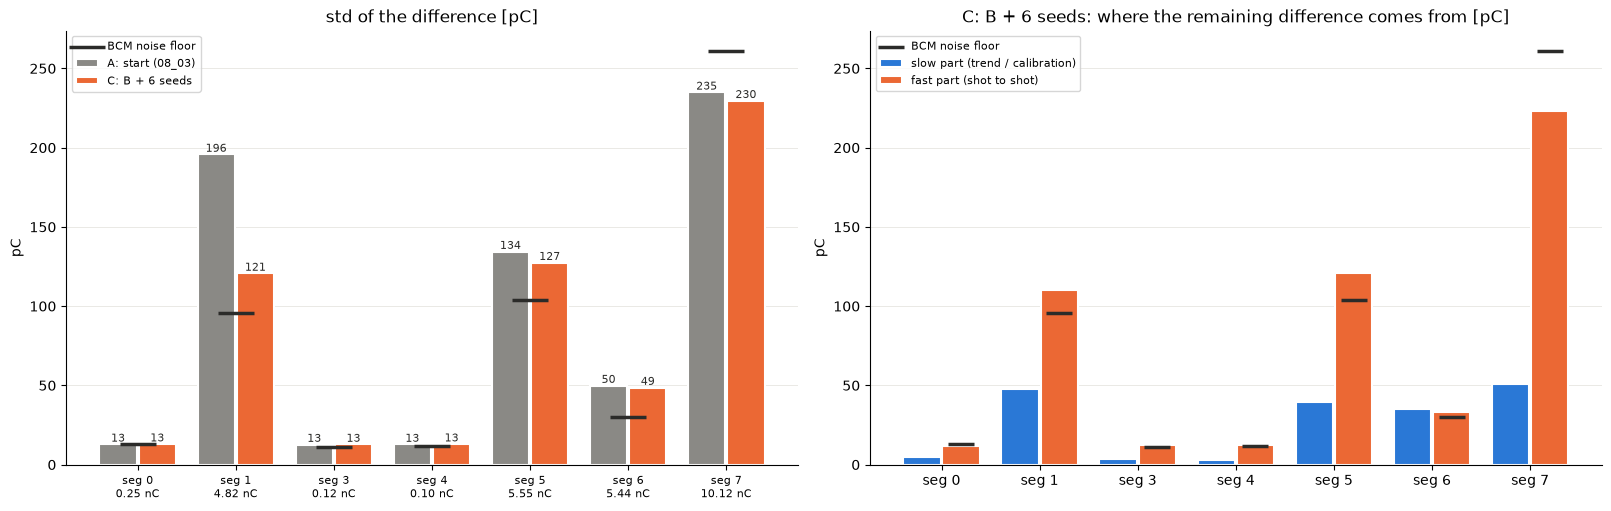

In [11]:
FINAL = "C: B + 6 seeds"
fig, axes = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
x = np.arange(len(segments))

ax = axes[0]
for dx, name, color in [(-0.2, "A: start (08_03)", BEFORE), (0.2, FINAL, AFTER)]:
    vals_ = [res.loc[(k, name), "std [pC]"] for k in segments]
    ax.bar(x + dx, vals_, width=0.38, color=color, label=name, edgecolor="white", linewidth=1.5)
    for xi, v_ in zip(x + dx, vals_):
        ax.text(xi, v_, f"{v_:.0f}", ha="center", va="bottom", fontsize=8, color=INK)
ax.scatter(x, floor["BCM noise floor [pC]"], marker="_", s=700, linewidths=2.5, color=FLOOR, label="BCM noise floor", zorder=3)
ax.set_xticks(x, [f"seg {k}\n{s['y'][s['test']].mean():.2f} nC" for k, s in segments.items()], fontsize=8)
ax.set(title="std of the difference [pC]", ylabel="pC")
ax.legend(fontsize=8)

ax = axes[1]
slow_ = [res.loc[(k, FINAL), "slow [pC]"] for k in segments]
fast_ = [res.loc[(k, FINAL), "fast [pC]"] for k in segments]
ax.bar(x - 0.2, slow_, width=0.38, color="#2a78d6", label="slow part (trend / calibration)", edgecolor="white", linewidth=1.5)
ax.bar(x + 0.2, fast_, width=0.38, color=AFTER, label="fast part (shot to shot)", edgecolor="white", linewidth=1.5)
ax.scatter(x + 0.2, floor["BCM noise floor [pC]"], marker="_", s=350, linewidths=2.5, color=FLOOR, label="BCM noise floor", zorder=3)
ax.set_xticks(x, [f"seg {k}" for k in segments])
ax.set(title=f"{FINAL}: where the remaining difference comes from [pC]", ylabel="pC")
ax.legend(fontsize=8)
for ax in axes:
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
fig.savefig(FIGS / "std_pc_before_after.png", dpi=130, bbox_inches="tight")

## Difference distributions, before and after (pC)

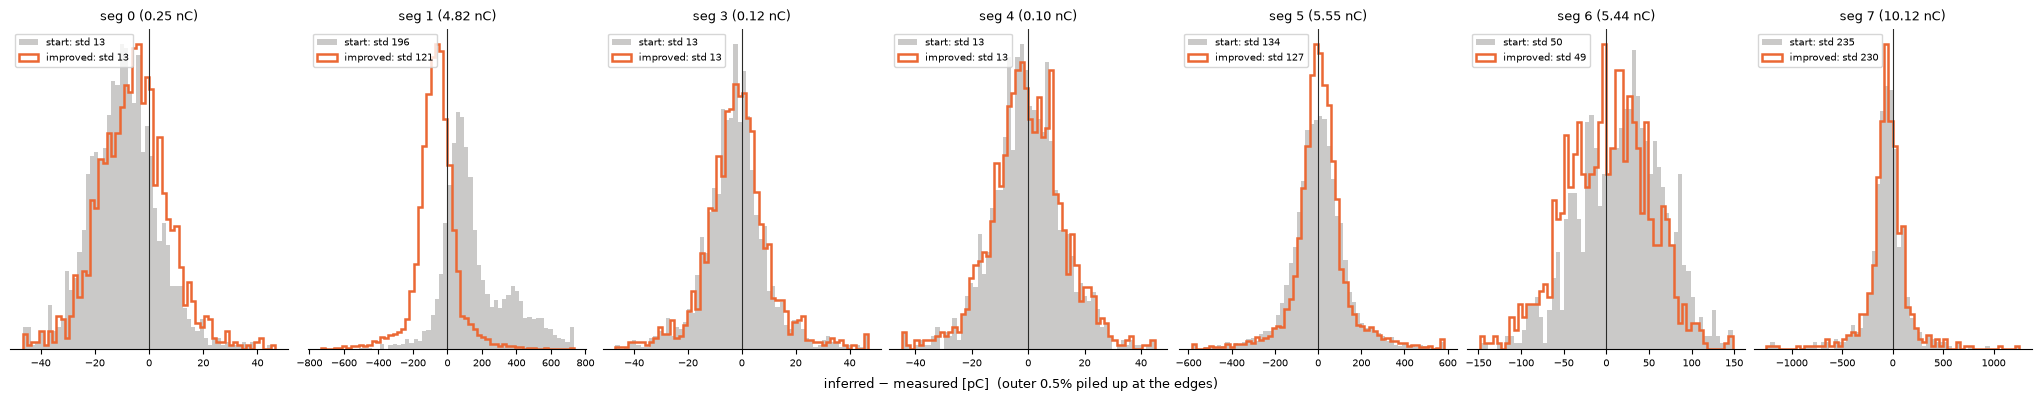

In [12]:
fig, axes = plt.subplots(1, len(segments), figsize=(2.9 * len(segments), 3.9), layout="constrained")
for ax, (k, s) in zip(axes, segments.items()):
    t = s["test"]
    e_before = PC * (preds[k]["A: start (08_03)"][t] - s["y"][t])
    e_after = PC * (preds[k][FINAL][t] - s["y"][t])
    lim = np.percentile(np.abs(np.r_[e_before, e_after]), 99.5) * 1.05
    bins = np.linspace(-lim, lim, 61)
    ax.hist(np.clip(e_before, -lim, lim), bins=bins, color=BEFORE, alpha=0.45, label=f"start: std {e_before.std():.0f}")
    ax.hist(np.clip(e_after, -lim, lim), bins=bins, histtype="step", lw=1.8, color=AFTER, label=f"improved: std {e_after.std():.0f}")
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_title(f"seg {k} ({s['y'][t].mean():.2f} nC)", fontsize=9)
    ax.legend(fontsize=7, loc="upper left")
    ax.tick_params(labelsize=7)
    ax.set_yticks([])
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
fig.supxlabel("inferred − measured [pC]  (outer 0.5% piled up at the edges)", fontsize=9)
fig.savefig(FIGS / "difference_before_after.png", dpi=130, bbox_inches="tight");

## Save the improved predictions (read by 08_04)

In [13]:
frames = []
for k, s in segments.items():
    t = s["test"]
    frames.append(pd.DataFrame({"segment": k, "run": s["run"], "shot": np.flatnonzero(t), "measured": s["y"][t],
                                "improved (08_05)": preds[k][FINAL][t], "MLP · CCC": preds[k]["A: start (08_03)"][t]}))
pd.concat(frames).to_csv(OUT / "predictions_08_05.csv", index=False)
print(f"saved {OUT / 'predictions_08_05.csv'}; stage-1 windows: {s1_window}")

saved /Users/angilard/Desktop/Fast-Approximate/results/virtual_diagnostic/predictions_08_05.csv; stage-1 windows: {0: 2000, 1: 4000, 3: 1000, 4: None, 5: 4000, 6: 2000, 7: None}


## Per-segment results of the improved model (as in 08_04)

Same plots as notebook 08_04, for the improved model **C** (orange / blue), with the starting model **A** of 08_03
drawn in grey for comparison. Differences in pC.

In [14]:
import sys
sys.path.insert(0, str(REPO / "scripts"))
import vd_plots   # summary table and plots, shared with 08_04

pred = pd.read_csv(OUT / "predictions_08_05.csv")
IMPROVED, START = "improved (08_05)", "MLP · CCC"
table = pd.concat({"improved (C)": vd_plots.summary_table(pred, IMPROVED),
                   "start (A, 08_03)": vd_plots.summary_table(pred, START)}, axis=1)
cols = ["bias [pC]", "std diff [pC]", "95% of |diff| below [pC]", "max |diff| [pC]", "corr of fluctuations"]
table = table.loc[:, [(m, c) for c in cols for m in ["start (A, 08_03)", "improved (C)"]]]
table.style.format({col: vd_plots.TABLE_FORMAT[col[1]] for col in table.columns})

,"start (A, 08_03)",improved (C),"start (A, 08_03)",improved (C),"start (A, 08_03)",improved (C),"start (A, 08_03)",improved (C),"start (A, 08_03)",improved (C)
,bias [pC],bias [pC],std diff [pC],std diff [pC],95% of |diff| below [pC],95% of |diff| below [pC],max |diff| [pC],max |diff| [pC],corr of fluctuations,corr of fluctuations
segment,,,,,,,,,,
0,-9.3,-5.8,12.8,12.9,30.2,27.6,66.8,64.5,0.84,0.84
1,+157.5,-66.9,195.7,120.6,544.3,279.6,1450.3,920.3,0.76,0.76
3,-2.2,-1.6,12.7,12.7,27.0,26.6,106.9,104.8,0.63,0.63
4,-0.4,-0.3,12.7,12.9,24.9,26.0,62.5,62.6,0.66,0.66
5,+2.8,+10.6,134.4,127.4,289.3,285.7,982.9,949.0,0.71,0.73
6,+17.8,+0.9,49.9,48.6,98.3,93.5,185.9,177.9,0.97,0.98
7,-56.3,-57.0,234.9,229.6,488.0,472.8,1876.9,1663.7,0.94,0.94


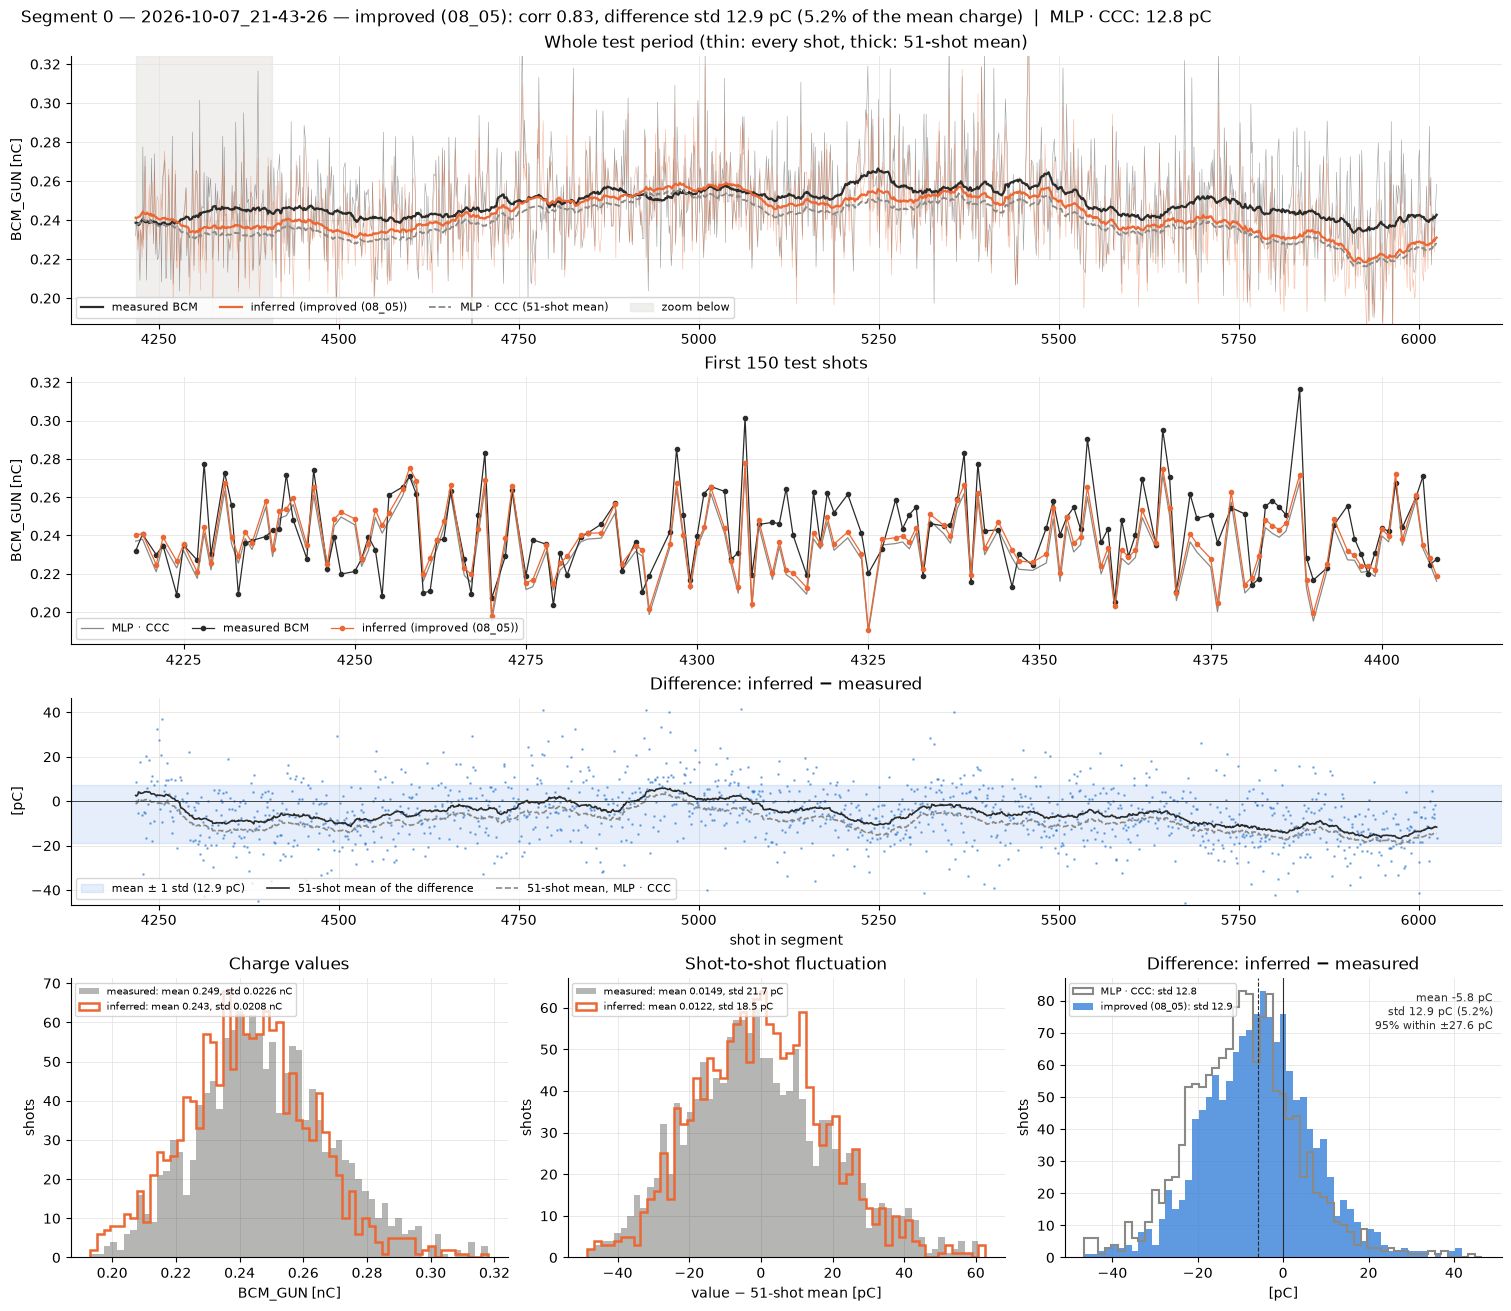

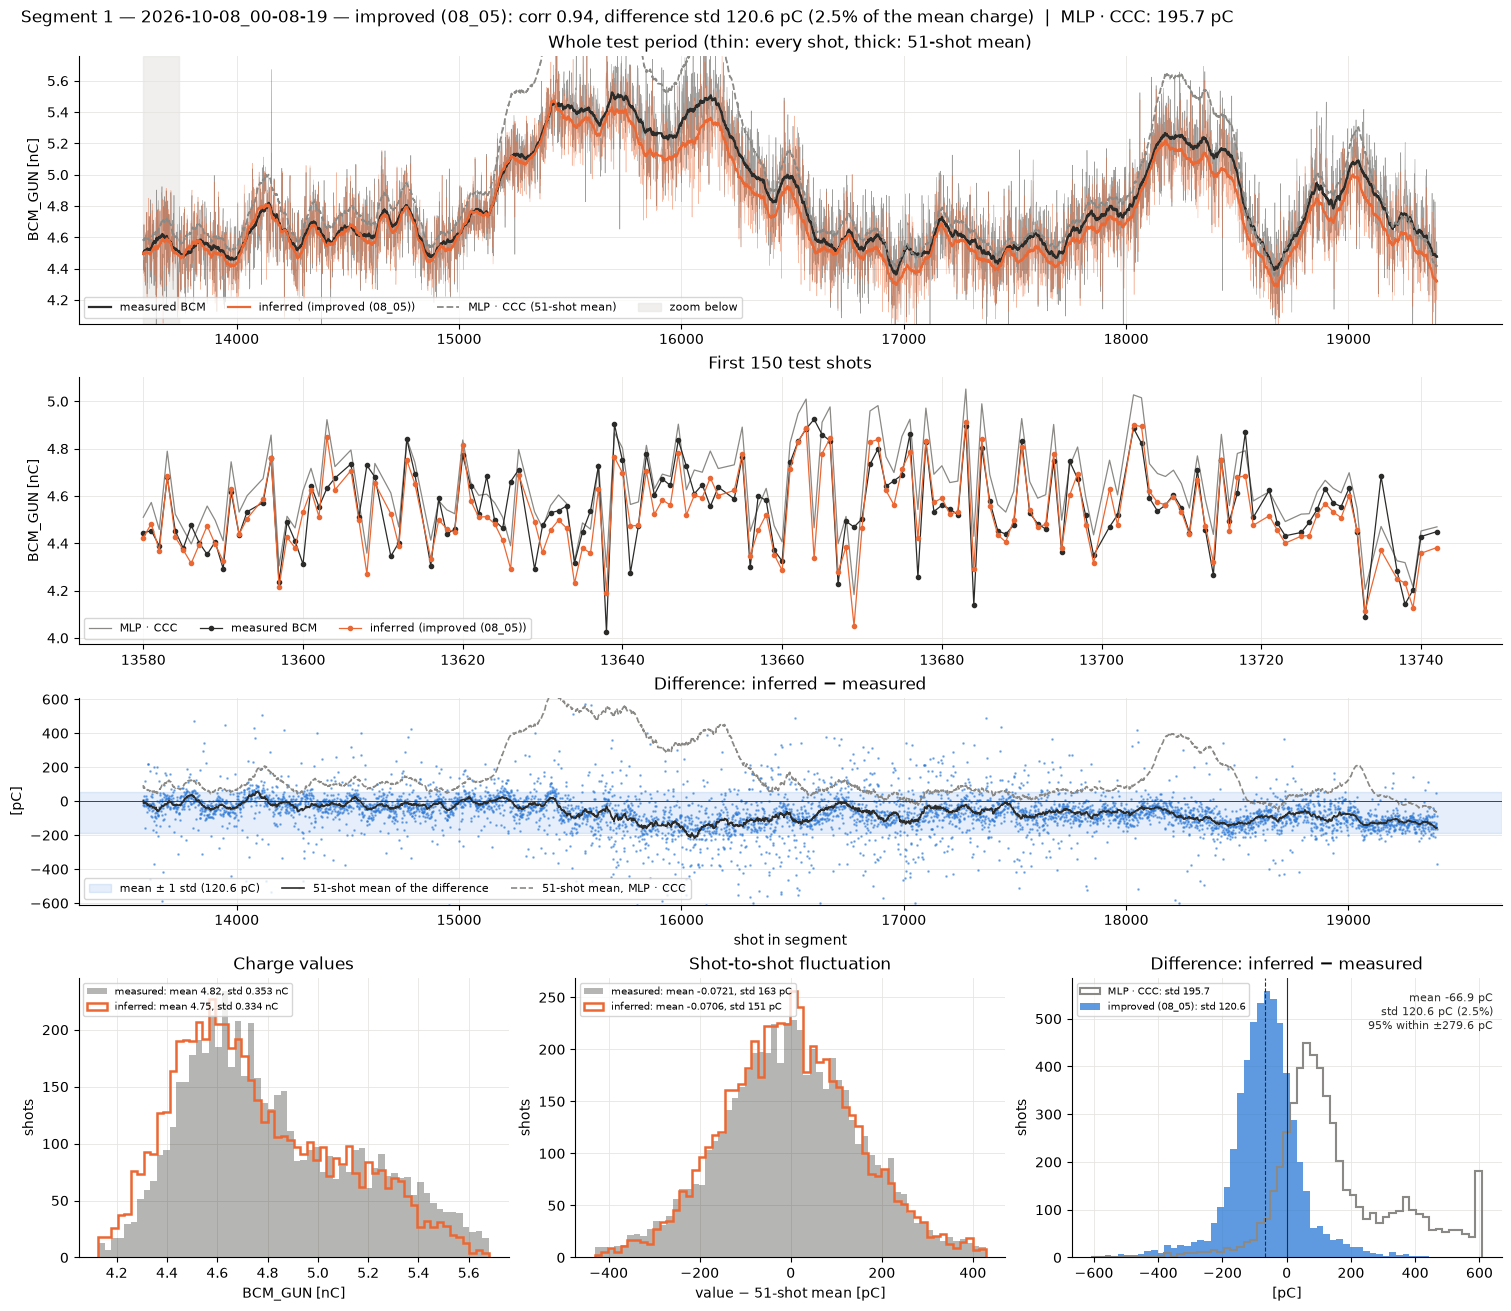

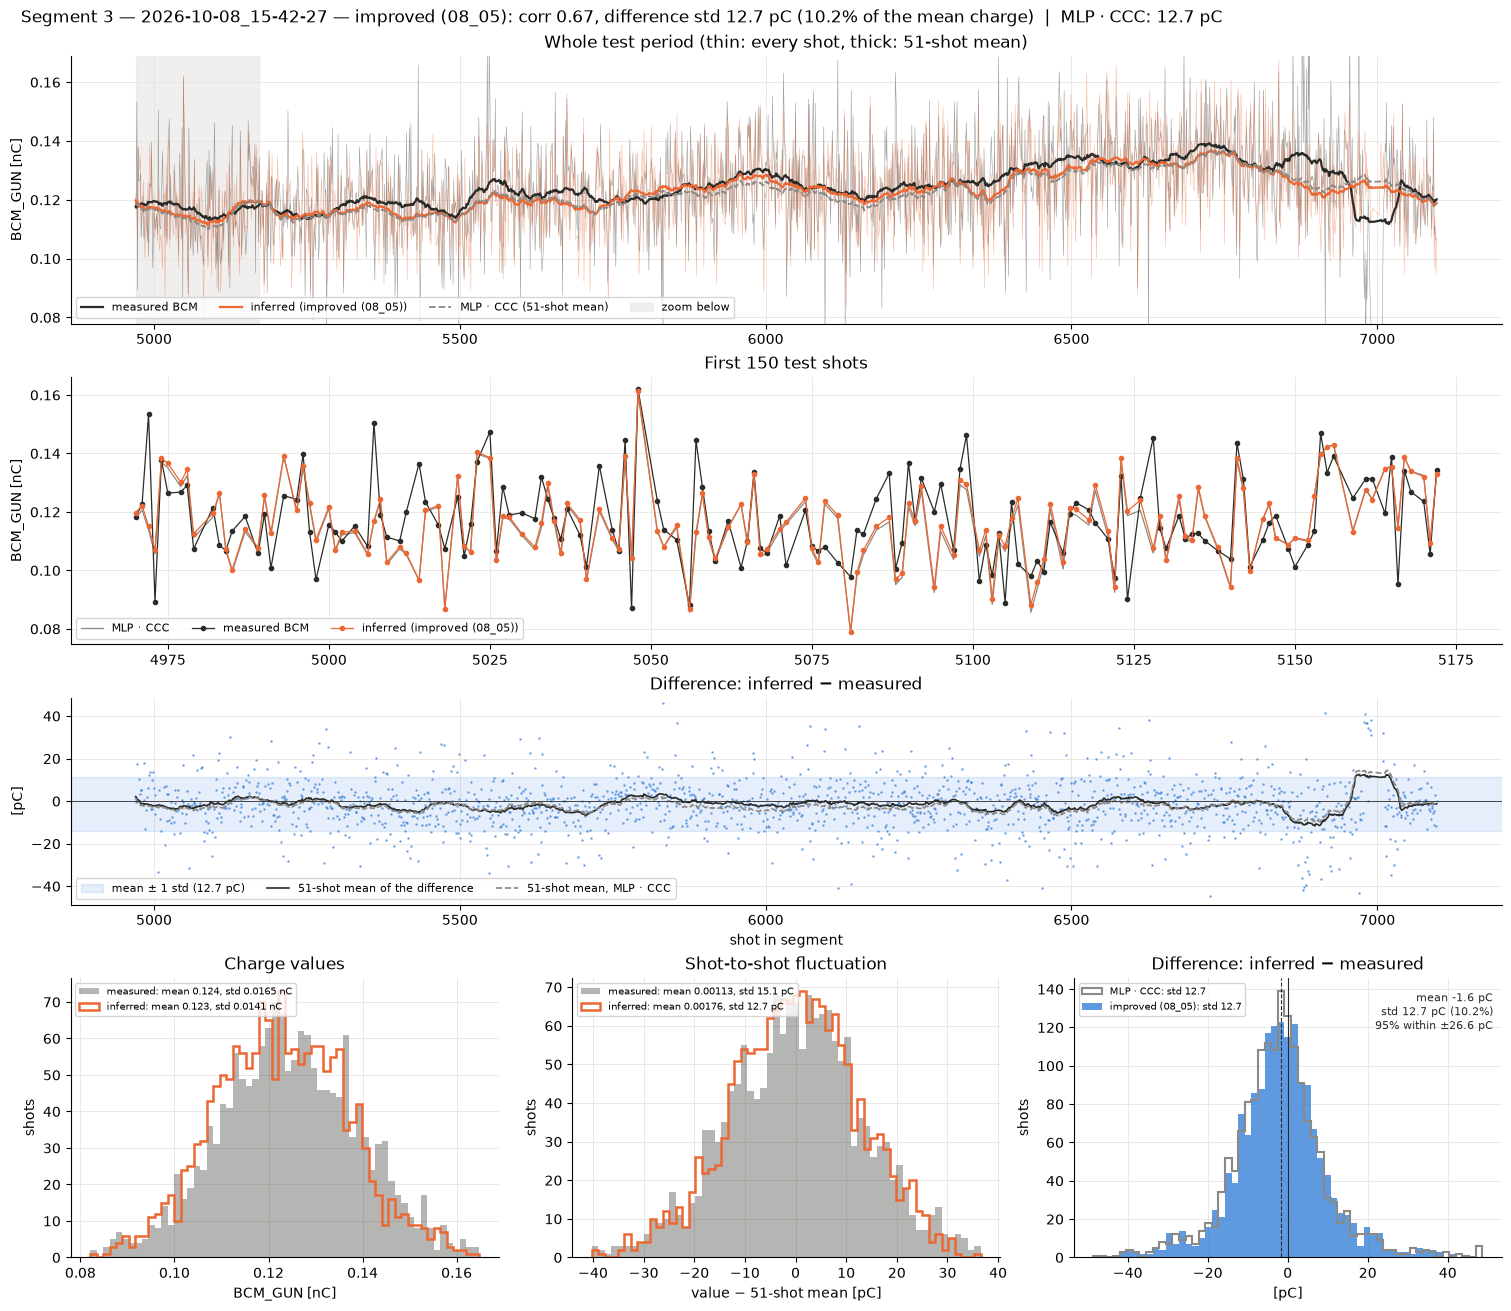

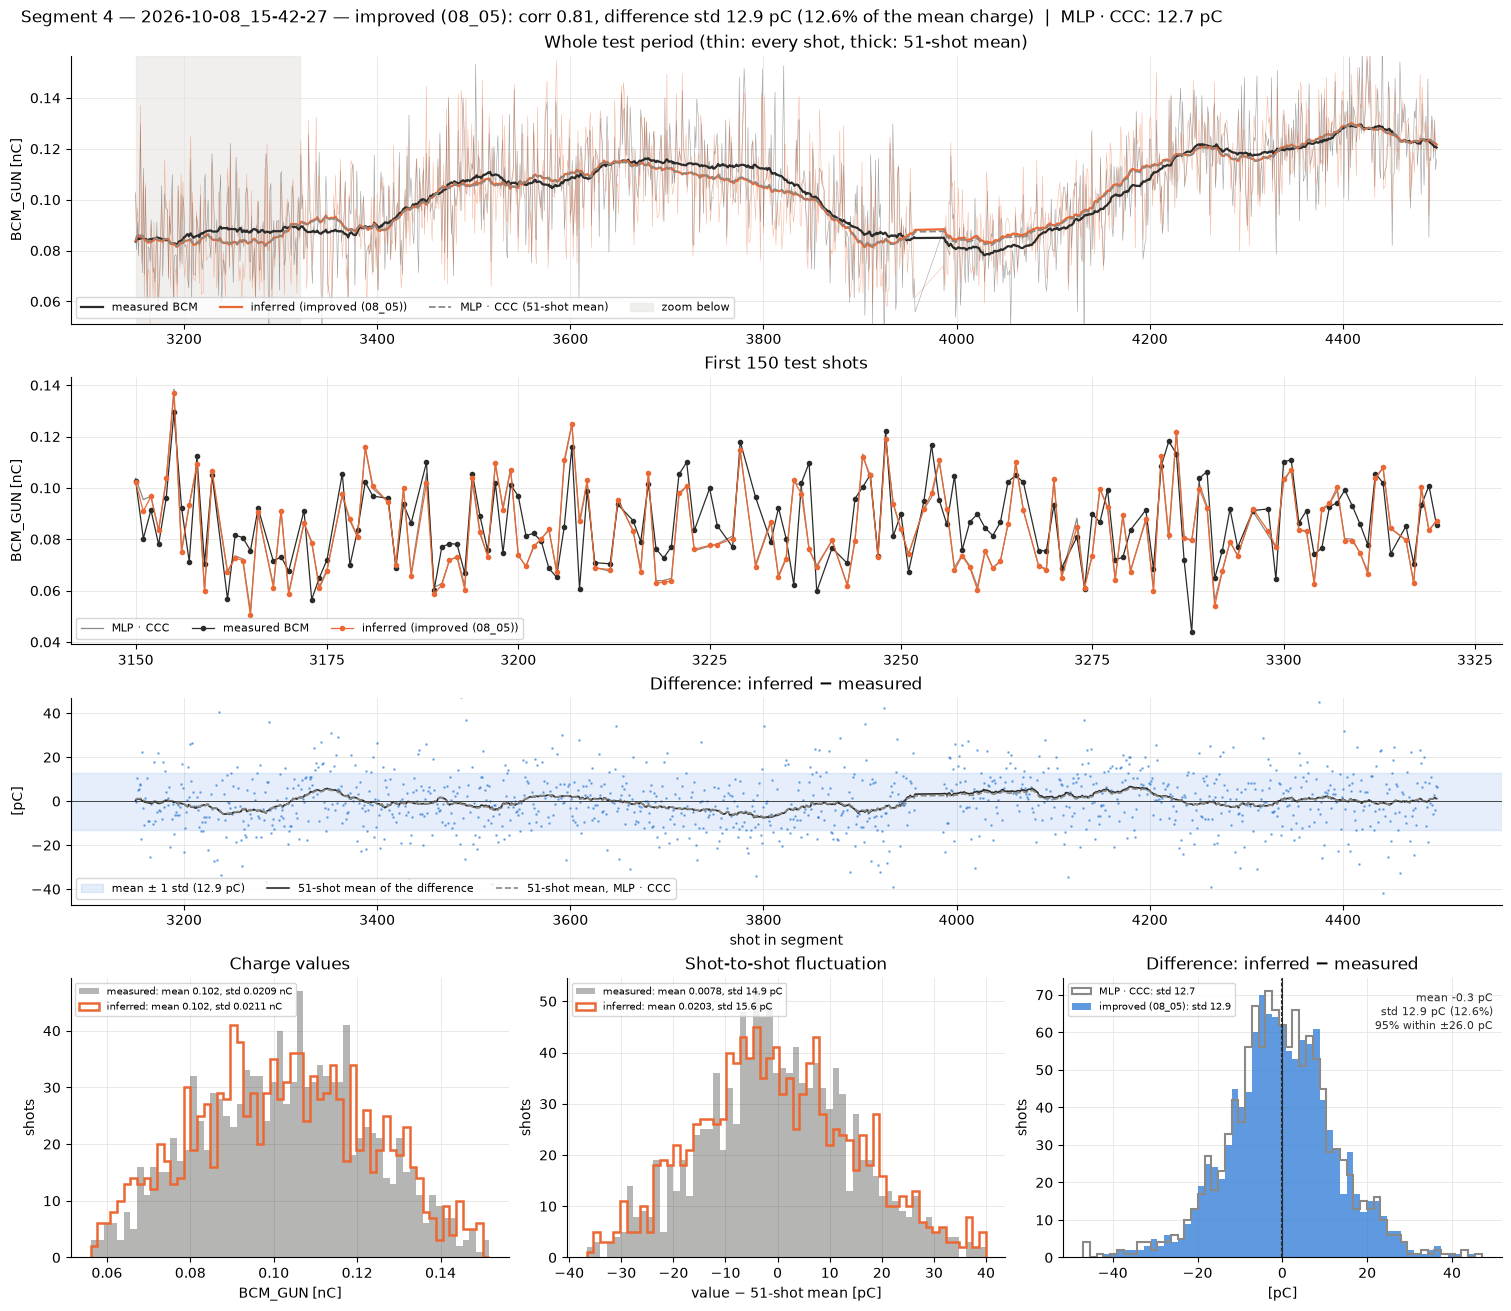

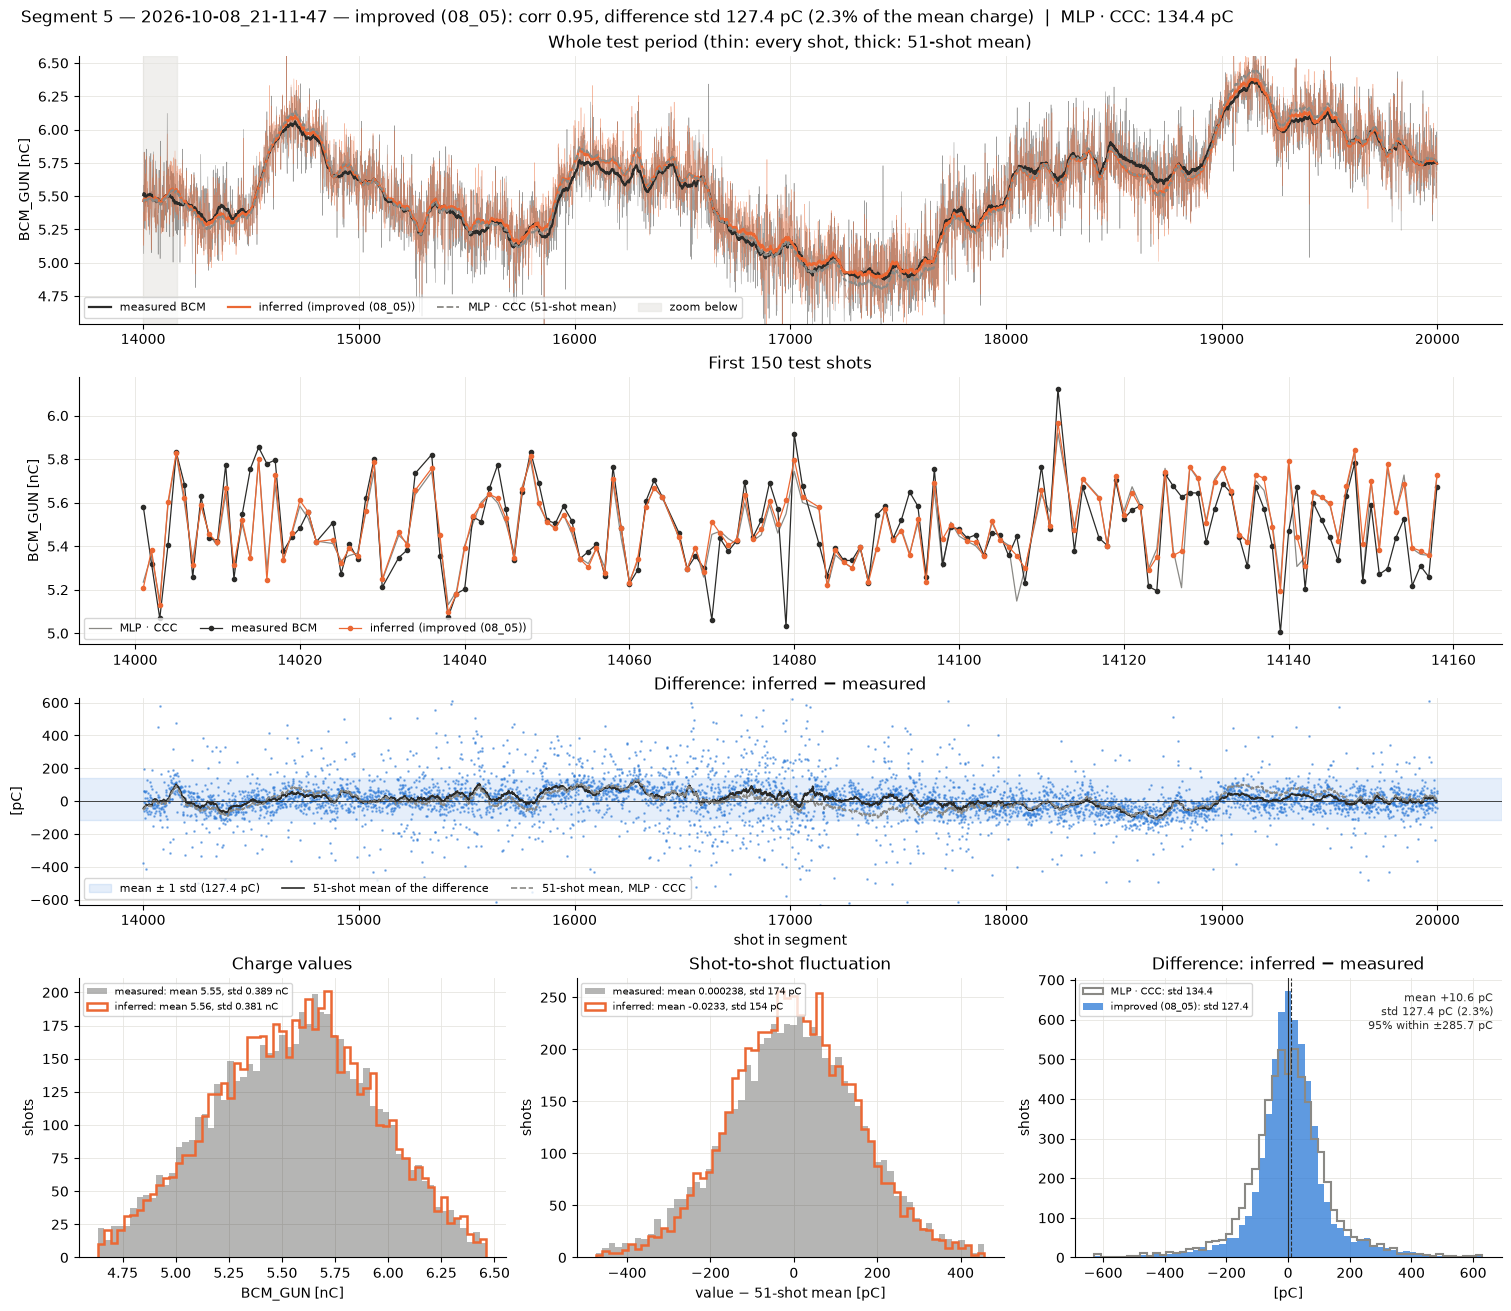

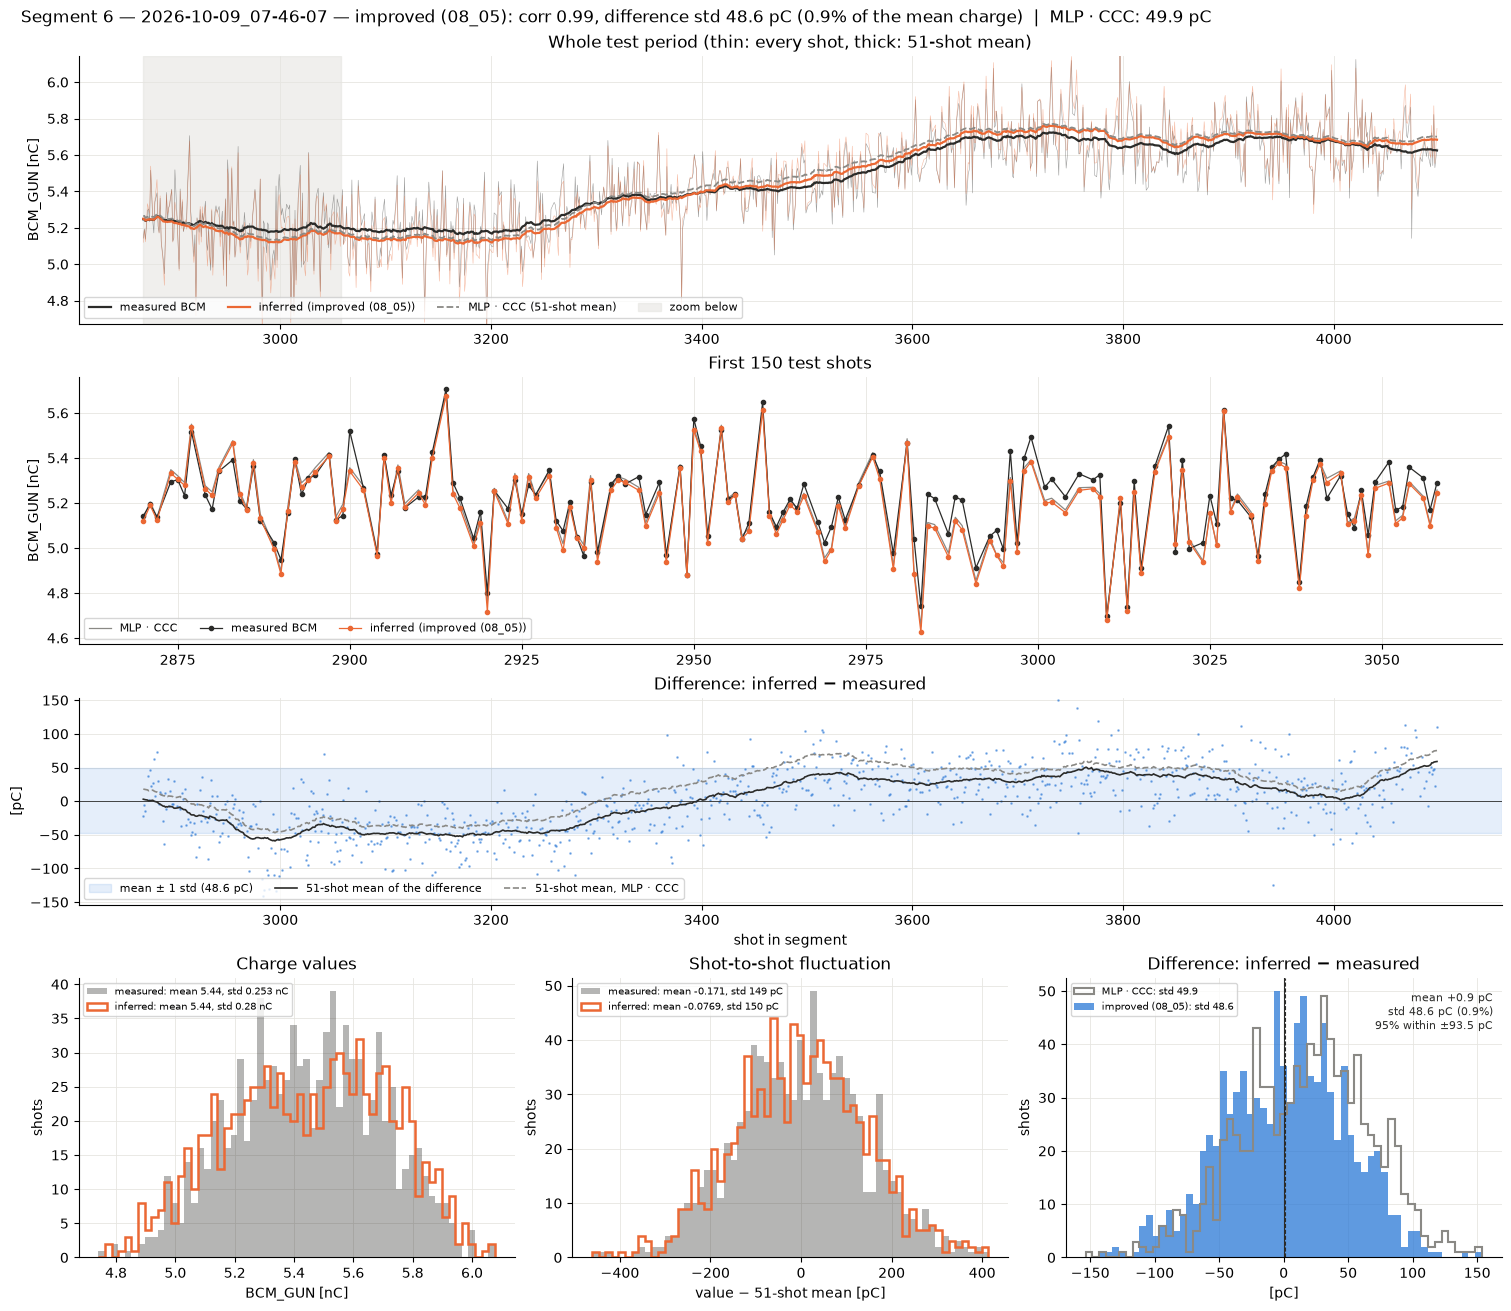

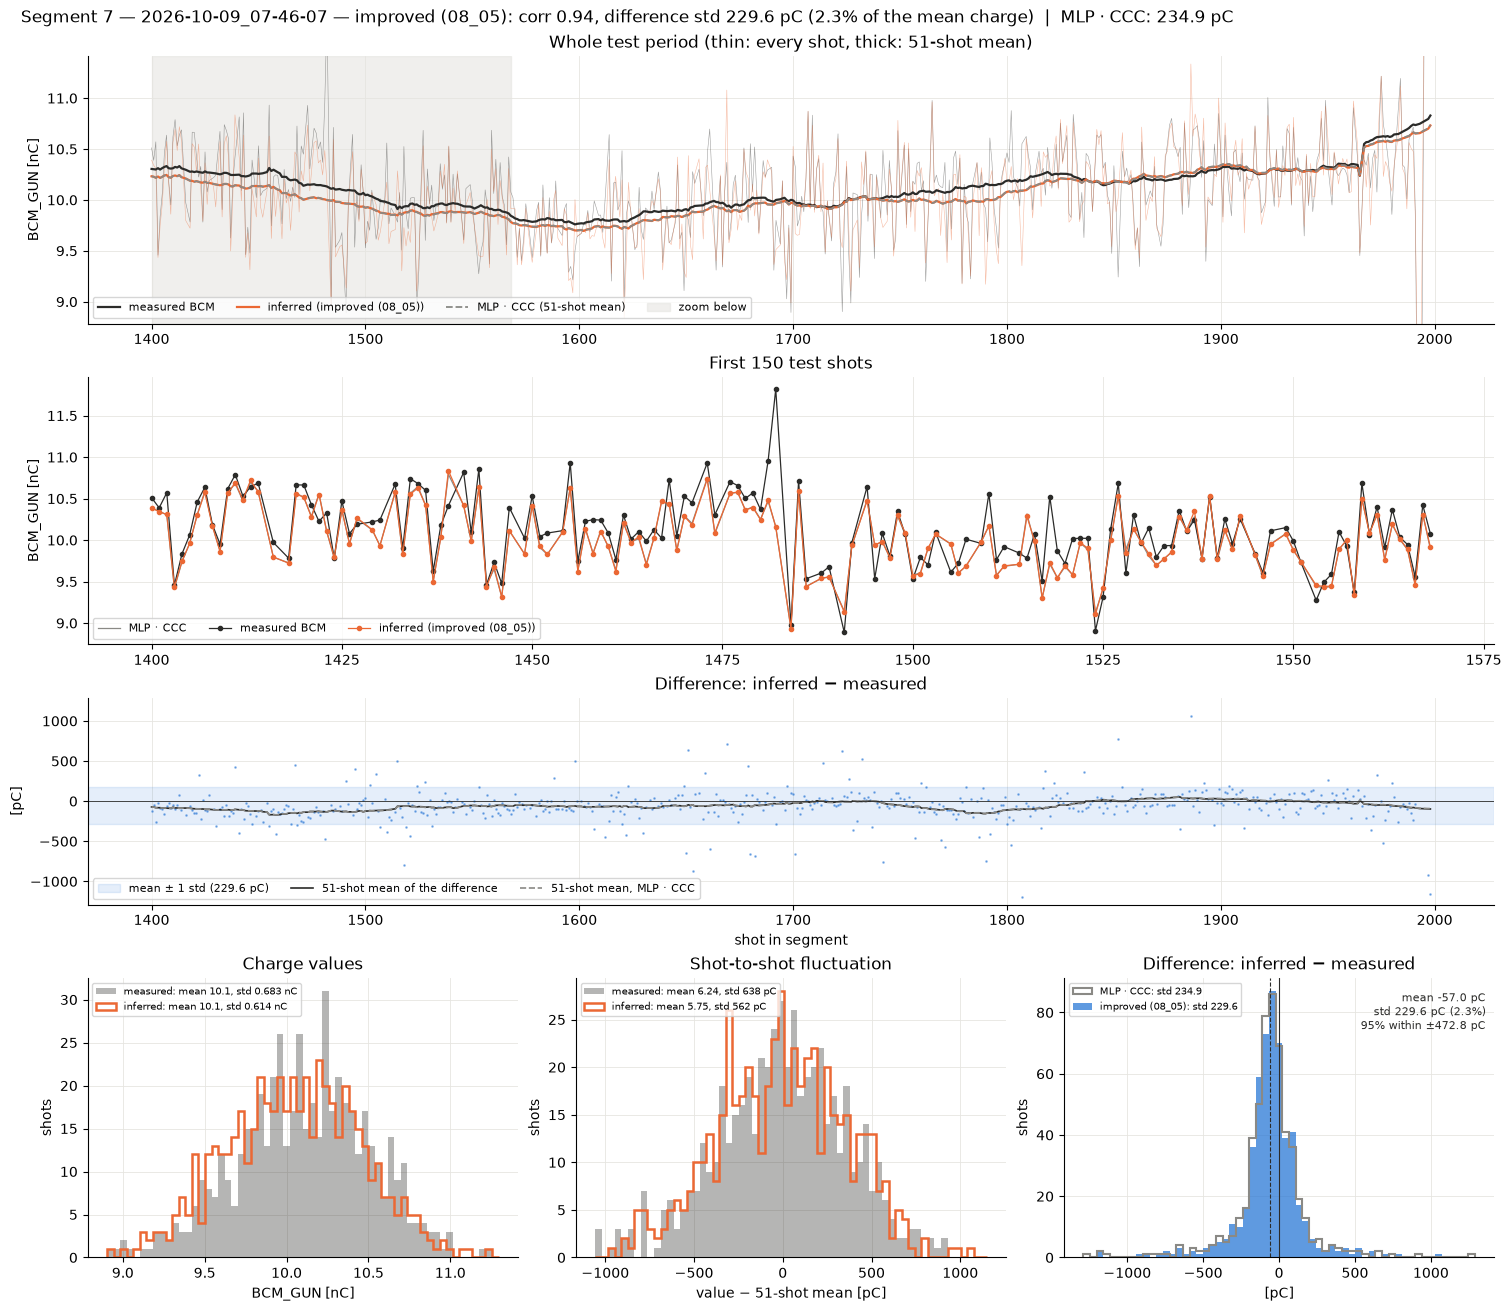

In [15]:
for k in sorted(pred["segment"].unique()):
    vd_plots.segment_figure(pred, k, IMPROVED, compare=START, save_dir=FIGS)

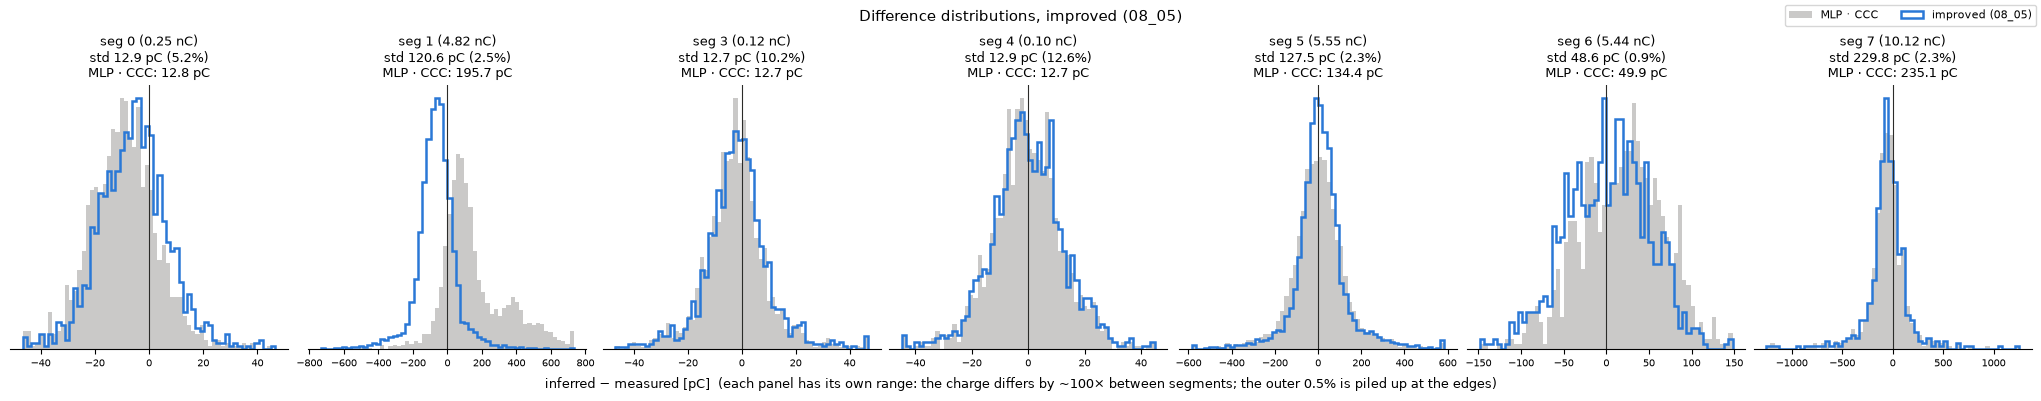

In [16]:
vd_plots.difference_all_segments(pred, IMPROVED, compare=START, save_path=FIGS / "difference_all_segments.png")